In [62]:
import urllib.parse
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

SERVIDOR = "LOCALHOST"
BASE = "NORTHWND1"

cadena = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={SERVIDOR};"
    f"DATABASE={BASE};"
    "Trusted_Connection=yes;"
)
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + urllib.parse.quote_plus(cadena))

with engine.connect() as conn:
    print(conn.execute(text("SELECT @@VERSION")).scalar())

Microsoft SQL Server 2025 (RTM) - 17.0.1000.7 (X64) 
	Oct 21 2025 12:05:57 
	Copyright (C) 2025 Microsoft Corporation
	Standard Developer Edition (64-bit) on Windows 10 Pro 10.0 <X64> (Build 26100: ) (Hypervisor)



In [14]:
pd.read_sql(text("SELECT TOP 5 * FROM Orders"), engine)

,OrderID,CustomerID,EmployeeID,OrderDate,RequiredDate,ShippedDate,ShipVia,Freight,ShipName,ShipAddress,ShipCity,ShipRegion,ShipPostalCode,ShipCountry
0,10248,VINET,5,2016-07-04,2016-08-01,2016-07-16,3,32.38,Vins et alcools Chevalier,59 rue de l'Abbaye,Reims,NaN,51100,France
1,10249,TOMSP,6,2016-07-05,2016-08-16,2016-07-10,1,11.61,Toms Spezialitäten,Luisenstr. 48,Münster,NaN,44087,Germany
2,10250,HANAR,4,2016-07-08,2016-08-05,2016-07-12,2,65.83,Hanari Carnes,"Rua do Paço, 67",Rio de Janeiro,RJ,05454-876,Brazil
3,10251,VICTE,3,2016-07-08,2016-08-05,2016-07-15,1,41.34,Victuailles en stock,"2, rue du Commerce",Lyon,NaN,69004,France
4,10252,SUPRD,4,2016-07-09,2016-08-06,2016-07-11,2,51.30,Suprêmes délices,"Boulevard Tirou, 255",Charleroi,NaN,B-6000,Belgium


In [59]:
# ¿Cómo evolucionan las ventas por mes?

with open("../sql/ventas_totales_mensual.sql", encoding="utf-8") as f:
    ventas = pd.read_sql(text(f.read()), engine)

total = pd.read_sql(
    text("SELECT SUM(UnitPrice * Quantity * (1 - Discount)) AS total FROM Order_Details"),
    engine
)["total"].iloc[0]
print(abs(ventas["total_ventas_mensual"].sum() - total) < 0.05)
print(ventas.head())

True
   anio  mes  total_ventas_mensual
0  2016    7              27861.89
1  2016    8              25485.27
2  2016    9              26381.40
3  2016   10              37515.73
4  2016   11              45600.04


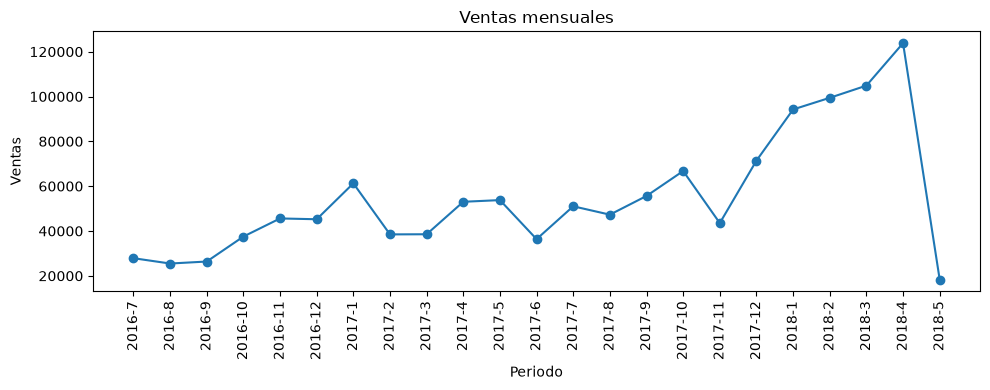

In [64]:
ventas["periodo"] = ventas["anio"].astype(str) + "-" + ventas["mes"].astype(str)

plt.figure(figsize=(10, 4))
plt.plot(ventas["periodo"], ventas["total_ventas_mensual"], marker="o")
plt.title("Ventas mensuales")
plt.ylabel("Ventas")
plt.xticks(rotation=90)
plt.xlabel("Periodo")
plt.tight_layout()

plt.savefig("../assets/ventas_mensuales.png", dpi=150)
plt.show()

In [ ]:
# ¿Cuáles son los 10 clientes que más compran?

with open("../sql/top_10_mejores_clientes.sql", encoding="utf-8") as f:
    clientes = pd.read_sql(text(f.read()), engine)

# print(clientes.shape)
# print(clientes.isna().sum())
# print(clientes.duplicated().sum())

print(clientes)

  CustomerID                   CompanyName  total_compras
0      QUICK                    QUICK-Stop  110277.304977
1      ERNSH                  Ernst Handel  104874.978714
2      SAVEA            Save-a-lot Markets  104361.949921
3      RATTC    Rattlesnake Canyon Grocery   51097.800333
4      HUNGO  Hungry Owl All-Night Grocers   49979.905001
5      HANAR                 Hanari Carnes   32841.369942
6      KOENE               Königlich Essen   30908.383984
7      FOLKO                Folk och fä HB   29567.562576
8      MEREP                Mère Paillarde   28872.190300
9      WHITC          White Clover Markets   27363.605043


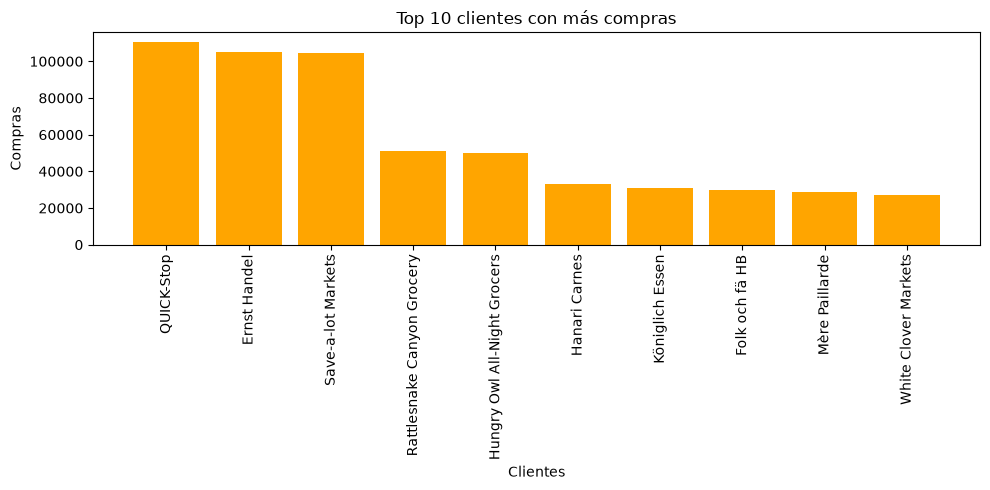

In [68]:
plt.figure(figsize=(10, 5))
plt.bar(clientes["CompanyName"], clientes["total_compras"], color="orange")
plt.title("Top 10 clientes con más compras")
plt.ylabel("Compras")
plt.xlabel("Clientes")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("../assets/clientes_compras.png", dpi=150)
plt.show()

In [ ]:
# ¿Qué países concentran las ventas?

with open("../sql/paises_con_mas_ventas.sql", encoding="utf-8") as f:
    paises = pd.read_sql(text(f.read()), engine)

print(paises)

        Country   total_ventas
0           USA  245584.610228
1       Germany  230284.633333
2       Austria  128003.838745
3        Brazil  106925.776361
4        France   81358.322476
5            UK   58971.310063
6     Venezuela   56810.629002
7        Sweden   54495.140045
8        Canada   50196.290321
9       Ireland   49979.905001
10      Belgium   33824.854980
11      Denmark   32661.022346
12  Switzerland   31692.658903
13       Mexico   23582.077625
14      Finland   18810.052570
15        Spain   17983.200107
16        Italy   15770.154905
17     Portugal   11472.362656
18    Argentina    8119.099976
19       Norway    5735.150000
20       Poland    3531.949976


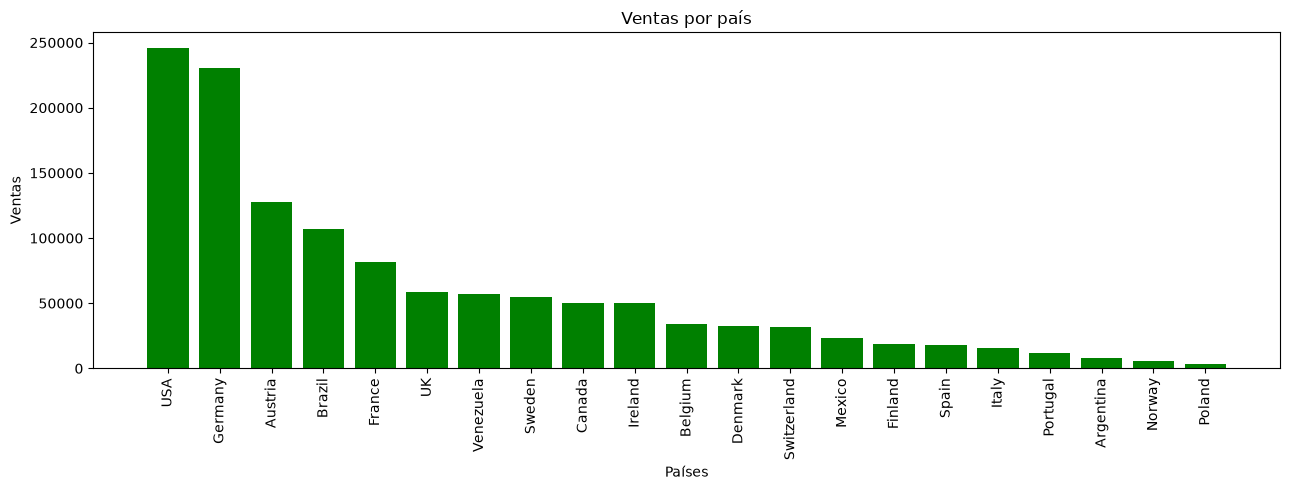

In [72]:
plt.figure(figsize=(13, 5))
plt.bar(paises["Country"], paises["total_ventas"], color="green")
plt.title("Ventas por país")
plt.ylabel("Ventas")
plt.xlabel("Países")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("../assets/paises_ventas.png", dpi=150)
plt.show()

In [48]:
# ¿Cuántos pedidos se envían después de la fecha requerida?

with open("../sql/pedidos_enviados_tarde.sql", encoding="utf-8") as f:
    pedidos = pd.read_sql(text(f.read()), engine)

print(pedidos)

   pedidos_enviados_tarde
0                      37


In [49]:
# ¿Qué empleados venden más?

with open("../sql/empleados_venden_mas.sql", encoding="utf-8") as f:
    empleados = pd.read_sql(text(f.read()), engine)

print(empleados)

   EmployeeID   Nombre_Empleado   total_ventas
0           4  Margaret Peacock  232890.845947
1           3   Janet Leverling  202812.842793
2           1     Nancy Davolio  192107.604321
3           2     Andrew Fuller  166537.754978
4           8    Laura Callahan  126862.277704
5           7       Robert King  124568.235382
6           9    Anne Dodsworth   77308.066710
7           6    Michael Suyama   73913.129244
8           5   Steven Buchanan   68792.282539


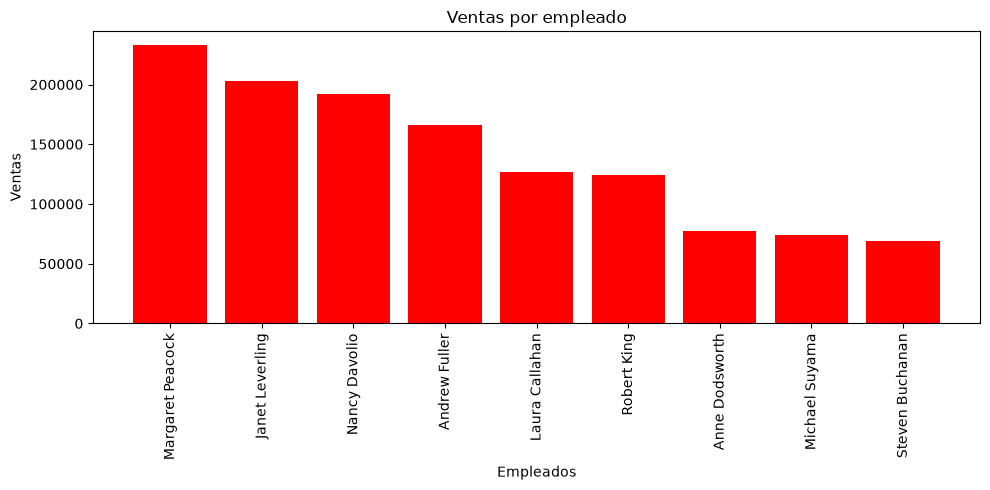

In [78]:
plt.figure(figsize=(10, 5))
plt.bar(empleados["Nombre_Empleado"], empleados["total_ventas"], color="red")
plt.title("Ventas por empleado")
plt.ylabel("Ventas")
plt.xlabel("Empleados")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("../assets/empleado_ventas.png", dpi=150)
plt.show()

In [ ]:
# ¿Qué categorías y productos generan más ingresos?

with open("../sql/categorias_productos_mas_ingresos.sql", encoding="utf-8") as f:
    categorias_productos = pd.read_sql(text(f.read()), engine)

print(categorias_productos)

      CategoryName                       ProductName  total_ingresos
0        Beverages                     Côte de Blaye   141396.735229
1     Meat/Poultry           Thüringer Rostbratwurst    80368.671997
2   Dairy Products              Raclette Courdavault    71155.700027
3      Confections                    Tarte au sucre    47234.969902
4   Dairy Products                 Camembert Pierrot    46825.480133
5   Grains/Cereals            Gnocchi di nonna Alice    42593.060093
6          Produce             Manjimup Dried Apples    41819.650246
7     Meat/Poultry                      Alice Mutton    32698.379982
8          Seafood                  Carnarvon Tigers    29171.875000
9          Produce                 Rössle Sauerkraut    25696.639832
10  Dairy Products            Mozzarella di Giovanni    24900.129910
11       Beverages                       Ipoh Coffee    23526.700142
12     Confections            Sir Rodney's Marmalade    22563.359909
13         Produce   Uncle Bob's O

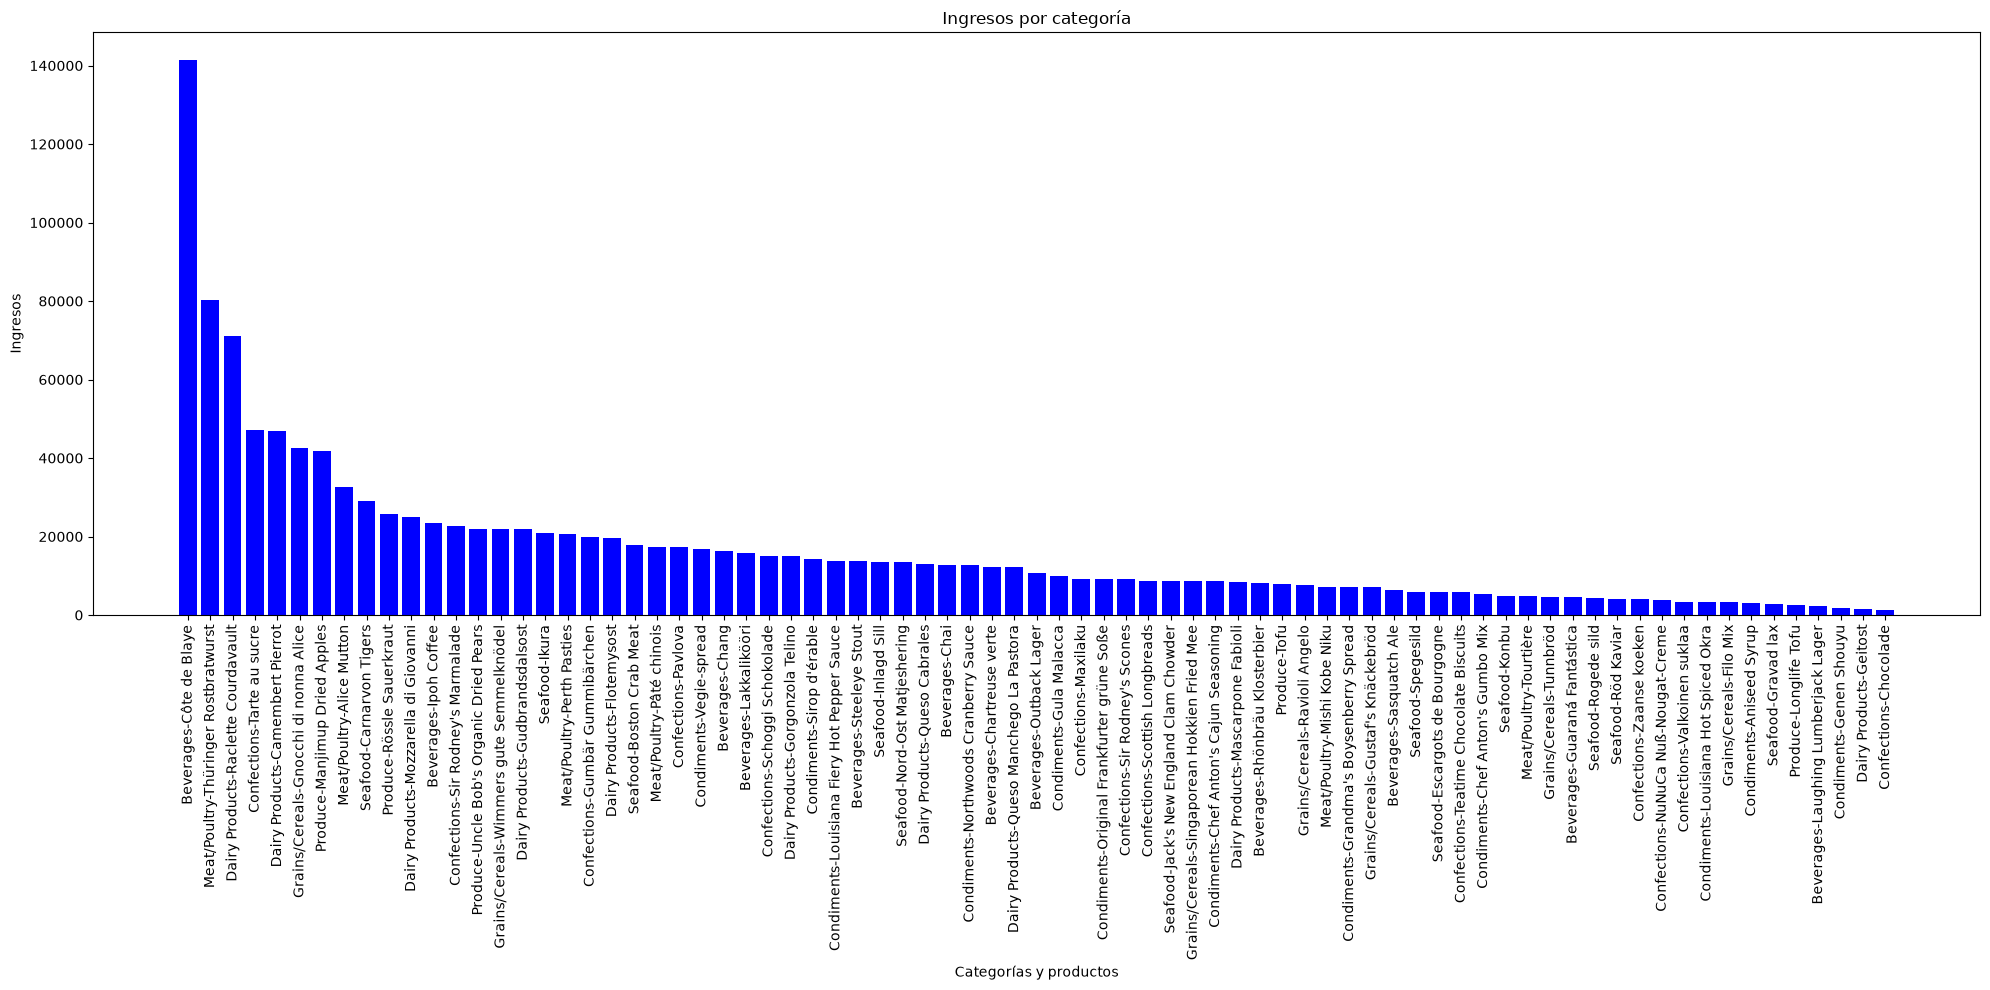

In [89]:
categorias_productos["CategoriaProductName"] = categorias_productos["CategoryName"] + "-" + categorias_productos["ProductName"]

plt.figure(figsize=(20, 10))
plt.bar(categorias_productos["CategoriaProductName"], categorias_productos["total_ingresos"], color="blue")
plt.title("Ingresos por categoría")
plt.ylabel("Ingresos")
plt.xlabel("Categorías y productos")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("../assets/productos_mas_ingresos.png", dpi=150)
plt.show()

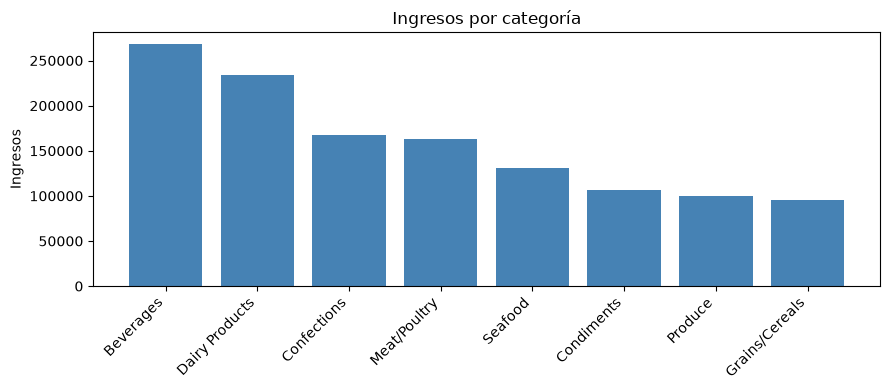

In [ ]:
por_categoria = categorias_productos.groupby("CategoryName")["total_ingresos"].sum()
por_categoria = por_categoria.sort_values(ascending=False)

plt.figure(figsize=(9, 4))
plt.bar(por_categoria.index, por_categoria.values, color="steelblue")
plt.title("Ingresos por categoría")
plt.ylabel("Ingresos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("../assets/ingresos_por_categoria.png", dpi=150)
plt.show()

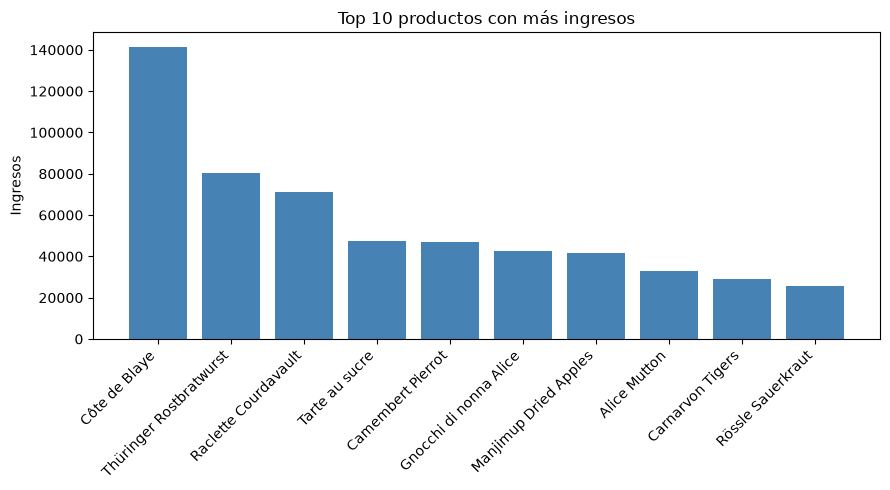

In [88]:
top_productos = categorias_productos.head(10)

plt.figure(figsize=(9, 5))
plt.bar(top_productos["ProductName"], top_productos["total_ingresos"], color="steelblue")
plt.title("Top 10 productos con más ingresos")
plt.ylabel("Ingresos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("../assets/top_10_productos.png", dpi=150)
plt.show()